# Phase 4 — 딥러닝: 오토인코더 기반 이상탐지

**지금까지의 최고 기록**: 평면 이탈 거리 단독 + contamination threshold → **Public 0.8294 / Private 0.8306**
(val: contamination macro-F1 0.7907, PR-AUC 0.6773)

**오토인코더란?** 입력을 작은 "병목(bottleneck)"으로 압축했다가 다시 원래대로 복원하도록 학습하는 신경망입니다.
대부분 정상인 train으로 학습하면 "정상 거래를 압축·복원하는 법"을 배우고, 처음 보는 패턴(사기)은 복원을 잘 못해서
**재구성 오차(입력과 출력의 차이)가 커집니다.** 이 오차를 이상 점수로 씁니다.

**이 노트북의 핵심 질문**
1. 거래의 88%가 한 평면 위에 있으니, 오토인코더는 그 평면을 "정상의 모양"으로 학습할 것이고, 평면 밖 거래는 복원이 잘 안 될 것이다.
   → **오토인코더가 우리가 손으로 찾은 평면을 스스로 찾아내는가?**
2. 그 결과 평면 이탈 거리 단독(리더보드 0.83)을 넘거나 보완할 수 있는가?

질문 1을 제대로 확인하려면 오토인코더에 힌트를 주면 안 되므로, 입력에서 **평면 이탈 거리를 뺀 피처 세트 C**
(V1~V28 + log 금액 + 시간대 sin/cos, 31개)를 씁니다.

(03b 노트북 섹션 12에서 저장한 피처 파일을 사용합니다.)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 03b에서 저장한 피처 불러오기
train_fe = pd.read_pickle('../data/train_fe.pkl')
val_fe = pd.read_pickle('../data/val_fe.pkl')
test_fe = pd.read_pickle('../data/test_fe.pkl')
y_true = val_fe['Class'].values

# 입력 피처: 세트 C (평면 이탈 거리 제외 → 오토인코더에 힌트를 주지 않음)
cols_C = [f'V{i}' for i in range(1, 29)] + ['log_amount', 'hour_sin', 'hour_cos']

# 비교·분석용 (입력으로는 쓰지 않음)
dist_train = train_fe['off_plane_dist'].values
dist_val = val_fe['off_plane_dist'].values
on_plane_val = dist_val < 1e-6

print('torch:', torch.__version__, '/ CUDA:', torch.cuda.is_available())
print('입력 피처 수:', len(cols_C))
print('train:', train_fe.shape, '/ val:', val_fe.shape, '/ test:', test_fe.shape)

torch: 2.8.0+cpu / CUDA: False
입력 피처 수: 31
train: (113842, 36) / val: (28462, 37) / test: (142503, 36)


## 공통 함수

03c와 같은 채점 함수입니다 (최적 macro-F1, contamination macro-F1, PR-AUC, ROC-AUC), 여기에 평면 위/밖 부분집합별 채점을 더했습니다.
contamination threshold를 쓰려면 train 점수도 필요하므로 모델마다 (train 점수, val 점수)를 같이 만듭니다.

In [4]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def find_best_threshold(y_true, scores, max_k=2000):
    # 점수 상위 k건을 사기로 예측하는 모든 경우(k=1~max_k)를 빠짐없이 탐색
    order = np.argsort(-scores)
    sorted_y = y_true[order]
    n_pos = y_true.sum()
    n_neg = len(y_true) - n_pos
    k = np.arange(1, max_k + 1)
    tp = np.cumsum(sorted_y)[:max_k]
    fp = k - tp
    fn = n_pos - tp
    tn = n_neg - fp
    macro = (2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2
    best_idx = np.argmax(macro)
    return scores[order][best_idx], macro[best_idx]

val_contamination = (y_true == 1).sum() / (y_true == 0).sum()   # 약 0.1055%

def evaluate(name, train_scores, val_scores):
    # 전체 성능 + 평면 위/밖 부분집합별 성능 (무작위 대비 몇 배)
    _, best_f1 = find_best_threshold(y_true, val_scores)
    threshold = np.quantile(train_scores, 1 - val_contamination)   # val 정답을 안 보는 threshold
    pred = (val_scores >= threshold).astype(int)
    row = {
        '모델': name,
        '최적 macro-F1': round(float(best_f1), 4),
        'contamination macro-F1': round(float(f1_score(y_true, pred, average='macro')), 4),
        'contamination 예측 건수': int(pred.sum()),
        'PR-AUC': round(float(average_precision_score(y_true, val_scores)), 4),
        'ROC-AUC': round(float(roc_auc_score(y_true, val_scores)), 4),
    }
    for subset_name, mask in [('평면 밖', ~on_plane_val), ('평면 위', on_plane_val)]:
        y_sub = y_true[mask]
        row[f'{subset_name} 배수'] = round(float(average_precision_score(y_sub, val_scores[mask]) / y_sub.mean()), 1)
    return row

results = [evaluate('평면 이탈 거리 단독 (기준)', dist_train, dist_val)]
display(pd.DataFrame(results))

,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC,평면 밖 배수,평면 위 배수
0,평면 이탈 거리 단독 (기준),0.8332,0.7907,25,0.6773,0.925,108.7,1.5


## 1. 준비: 스케일링

신경망은 경사하강법으로 학습하는데, 변수마다 값의 크기가 제각각이면(예: V1 표준편차 1.95, V28은 0.36) 큰 변수 쪽으로 학습이 쏠리고
불안정해집니다. 그래서 train 기준으로 평균 0, 표준편차 1로 맞춥니다 (val·test에도 train 기준을 그대로 적용).
PyTorch는 기본적으로 32비트 실수(float32)를 쓰므로 미리 바꿔둡니다.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(train_fe[cols_C])
X_tr = scaler.transform(train_fe[cols_C]).astype(np.float32)
X_va = scaler.transform(val_fe[cols_C]).astype(np.float32)
X_te = scaler.transform(test_fe[cols_C]).astype(np.float32)

print('X_tr:', X_tr.shape, X_tr.dtype)
print('train 평균(앞 5개 피처):', X_tr.mean(axis=0)[:5].round(4))
print('train 표준편차(앞 5개 피처):', X_tr.std(axis=0)[:5].round(4))

X_tr: (113842, 31) float32
train 평균(앞 5개 피처): [-0.  0.  0.  0.  0.]
train 표준편차(앞 5개 피처): [1. 1. 1. 1. 1.]


## 2. 워밍업: PCA 재구성 오차 = "선형 오토인코더"

PCA는 사실 가장 단순한 오토인코더입니다.
- **압축(인코더)**: 31개 피처를 분산이 큰 방향 k개로 투영 → k개 숫자로 요약
- **복원(디코더)**: 그 k개 숫자로 원래 31개 피처를 다시 계산
- **재구성 오차**: 버린 (31 - k)개 방향에 있던 정보 = 복원하지 못한 부분

PCA는 "평균적으로 가장 많이 퍼진 방향"부터 남깁니다. 그렇다면 평면 방향(거래의 88%가 두께 0인 방향)은
분산이 가장 작은 방향이라 버려질까요? 먼저 성분별 분산을 보고, 가장 작은 성분들이 평면 방향과 관련 있는지 확인합니다.

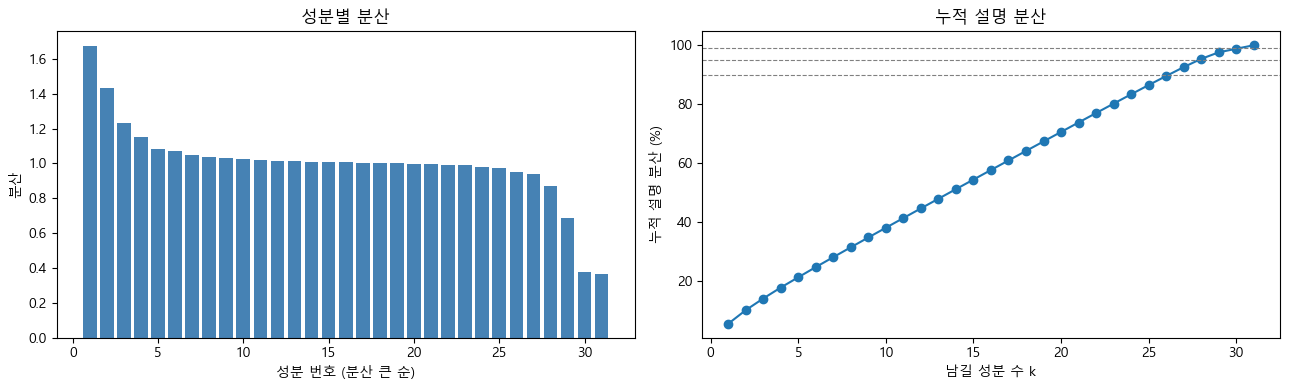

31번째 성분 (분산 0.368): 평면 이탈 거리와 순위 상관 0.047
30번째 성분 (분산 0.379): 평면 이탈 거리와 순위 상관 0.106
29번째 성분 (분산 0.687): 평면 이탈 거리와 순위 상관 0.331


In [6]:
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

pca_full = PCA().fit(X_tr)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, len(explained) + 1), pca_full.explained_variance_, color='steelblue')
axes[0].set_xlabel('성분 번호 (분산 큰 순)')
axes[0].set_ylabel('분산')
axes[0].set_title('성분별 분산')
axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100, marker='o')
for q in [90, 95, 99]:
    axes[1].axhline(q, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_xlabel('남길 성분 수 k')
axes[1].set_ylabel('누적 설명 분산 (%)')
axes[1].set_title('누적 설명 분산')
plt.tight_layout()
plt.show()

# 분산이 가장 작은 성분 3개: 그 성분 값의 크기가 평면 이탈 거리와 얼마나 같이 움직이나 (1에 가까울수록 같은 정보)
Z_va = pca_full.transform(X_va)
for j in [-1, -2, -3]:
    rho = spearmanr(np.abs(Z_va[:, j]), dist_val).correlation
    print(f'{len(explained) + j + 1}번째 성분 (분산 {pca_full.explained_variance_[j]:.3f}): 평면 이탈 거리와 순위 상관 {rho:.3f}')

## 3. 남길 성분 수(k)에 따라 재구성 오차가 사기를 얼마나 잘 가려내나

k는 오토인코더의 **병목 크기**에 해당합니다. k를 바꿔가며 재구성 오차를 점수로 채점합니다.

주의: 여기서 val 성능이 가장 좋은 k를 고르면, threshold를 val에 맞췄을 때와 똑같은 과적합이 됩니다.
정답 없이 k를 정하는 흔한 규칙은 "누적 설명 분산 90% / 95% / 99%를 처음 넘는 k"입니다. 이 규칙들이 각각 어떤 k를 고르는지도 같이 봅니다.

In [7]:
def pca_recon_error(k, X):
    # 성분 k개만 남겨서 압축했다가 복원했을 때, 원래 값과의 차이(제곱합)
    p = PCA(n_components=k).fit(X_tr)
    return ((X - p.inverse_transform(p.transform(X))) ** 2).sum(axis=1)

rule_k = {q: int(np.searchsorted(cumulative, q / 100) + 1) for q in [90, 95, 99]}
print('정답 없이 k를 고르는 규칙:', {f'{q}% 규칙': k for q, k in rule_k.items()})

pca_rows = []
for k in [5, 10, 15, 20, 25, 27, 28, 29, 30]:
    err_tr, err_va = pca_recon_error(k, X_tr), pca_recon_error(k, X_va)
    row = evaluate(f'PCA k={k}', err_tr, err_va)
    row['평면 이탈 거리와 순위 상관'] = round(float(spearmanr(err_va, dist_val).correlation), 3)
    pca_rows.append(row)

pca_results = pd.DataFrame(pca_rows)
display(pd.concat([pd.DataFrame(results), pca_results], ignore_index=True))

정답 없이 k를 고르는 규칙: {'90% 규칙': 27, '95% 규칙': 28, '99% 규칙': 31}


,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC,평면 밖 배수,평면 위 배수,평면 이탈 거리와 순위 상관
0,평면 이탈 거리 단독 (기준),0.8332,0.7907,25,0.6773,0.9250,108.7,1.5,NaN
1,PCA k=5,0.7379,0.6663,36,0.3465,0.9505,71.5,7.6,0.335
2,PCA k=10,0.7379,0.6715,34,0.3467,0.9471,73.2,7.1,0.325
3,PCA k=15,0.7442,0.6814,36,0.3808,0.9499,76.1,6.4,0.337
4,PCA k=20,0.7437,0.6997,35,0.3910,0.9668,78.7,9.3,0.354
5,PCA k=25,0.7498,0.7292,31,0.4404,0.9573,94.8,2.5,0.297
6,PCA k=27,0.7454,0.7292,31,0.4545,0.9622,98.9,3.2,0.231
7,PCA k=28,0.8749,0.8447,28,0.7082,0.9659,121.4,4.6,0.147
8,PCA k=29,0.5113,0.4996,21,0.0058,0.7826,5.0,4.7,0.132
9,PCA k=30,0.4997,0.4995,23,0.0021,0.6525,2.0,0.9,0.047


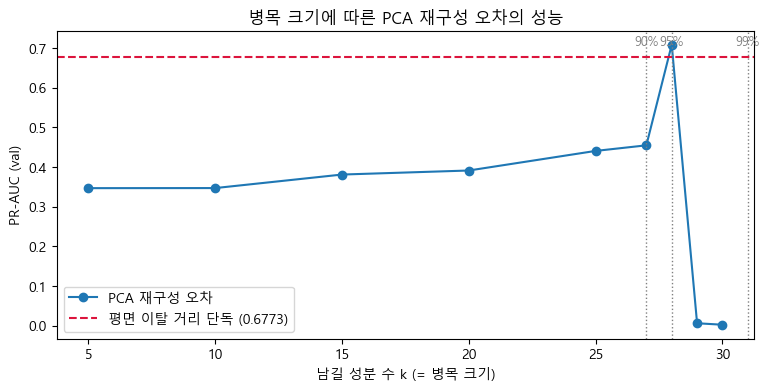

In [8]:
ks = [int(name.split('=')[1]) for name in pca_results['모델']]
plt.figure(figsize=(9, 4))
plt.plot(ks, pca_results['PR-AUC'], marker='o', label='PCA 재구성 오차')
plt.axhline(results[0]['PR-AUC'], color='crimson', linestyle='--', label=f"평면 이탈 거리 단독 ({results[0]['PR-AUC']})")
for q, k in rule_k.items():
    plt.axvline(k, color='gray', linestyle=':', linewidth=1)
    plt.text(k, plt.ylim()[1] * 0.95, f'{q}%', ha='center', fontsize=9, color='gray')
plt.xlabel('남길 성분 수 k (= 병목 크기)')
plt.ylabel('PR-AUC (val)')
plt.title('병목 크기에 따른 PCA 재구성 오차의 성능')
plt.legend()
plt.show()

## 4. 오토인코더 구조

```
입력 31 → 16 → [병목 8] → 16 → 출력 31
 \____ 인코더(압축) ____/   \___ 디코더(복원) ___/
```

- **nn.Linear(a, b)**: a개 숫자를 받아 b개 숫자를 내는 층. 각 출력은 입력들의 가중합 + 편향이고, 이 가중치가 학습 대상입니다.
- **ReLU**: 음수는 0으로, 양수는 그대로 통과. 이게 있어야 곡선(비선형) 관계를 표현할 수 있습니다. ReLU가 없으면 층을 아무리 쌓아도
  결국 PCA 같은 직선(선형) 변환과 같아집니다.
- **병목(8)**: 31개 정보를 8개 숫자로 억지로 요약하는 지점. 좁을수록 "정상의 핵심 패턴"만 남기게 됩니다.
  병목에는 ReLU를 두지 않아서 압축된 값이 음수도 가질 수 있게 합니다.
- **출력층**: 활성화 함수 없음. 표준화된 피처는 음수도 있어서 ReLU를 쓰면 음수를 복원할 수 없기 때문입니다.

병목 크기를 바꿔가며 실험할 수 있도록 병목 크기를 인자로 받게 만듭니다.

In [9]:
import torch
from torch import nn

class AutoEncoder(nn.Module):
    def __init__(self, n_features, bottleneck, hidden=16):
        super().__init__()
        # 인코더: 31 -> 은닉(기본 16) -> 병목 (점점 좁혀가며 압축)
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden), nn.ReLU(),
            nn.Linear(hidden, bottleneck),         # 병목: 활성화 함수 없음
        )
        # 디코더: 병목 -> 은닉(기본 16) -> 31 (다시 넓혀가며 복원)
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden), nn.ReLU(),
            nn.Linear(hidden, n_features),         # 출력층: 활성화 함수 없음 (음수도 복원해야 하므로)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))       # 압축했다가 복원

model_preview = AutoEncoder(n_features=X_tr.shape[1], bottleneck=8)
print(model_preview)
print('학습할 가중치 개수:', sum(p.numel() for p in model_preview.parameters()))

AutoEncoder(
  (encoder): Sequential(
    (0): Linear(in_features=31, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=31, bias=True)
  )
)
학습할 가중치 개수: 1319


## 5. 학습

**데이터 나누기**: train의 90%로 학습하고, 나머지 10%(홀드아웃)는 학습에 쓰지 않습니다. 홀드아웃의 역할은 두 가지입니다.
1. 에폭마다 홀드아웃 손실을 재서, 모델이 처음 보는 데이터에도 복원을 잘하는지(외우고 있지 않은지) 확인
2. 나중에 contamination threshold를 정할 때 사용. 03c에서 One-Class SVM이 학습한 train에 점수를 후하게 줘서 threshold가 망가졌던 것처럼,
   오토인코더도 학습한 거래는 복원을 더 잘할 수 있기 때문입니다.

val.csv는 여전히 채점에만 씁니다.

**학습 한 번(배치 하나)의 흐름**
1. 순전파: 배치(512개 거래)를 넣어 복원값을 계산
2. 손실: 복원값과 입력의 차이 (MSE, 오차 제곱의 평균)
3. 역전파: 손실을 줄이려면 각 가중치를 어느 방향으로 바꿔야 하는지(기울기) 계산
4. 가중치 갱신: Adam 옵티마이저가 기울기 방향으로 가중치를 조금 이동

이걸 train 전체에 대해 한 바퀴 돌면 1 에폭이고, 30 에폭 반복합니다. 1~2분 정도 걸립니다.

In [10]:
# train을 학습용 90% / 홀드아웃 10%로 무작위 분할
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_tr))
n_hold = len(X_tr) // 10
X_fit, X_hold = X_tr[perm[n_hold:]], X_tr[perm[:n_hold]]
print('학습용:', X_fit.shape, '/ 홀드아웃:', X_hold.shape)

def train_autoencoder(bottleneck, X_fit, X_hold, epochs=30, batch_size=512, lr=1e-3, seed=42, hidden=16, loss='MSE'):
    torch.manual_seed(seed)   # 가중치 초기값·배치 순서를 고정해서 매번 같은 결과가 나오게
    model = AutoEncoder(X_fit.shape[1], bottleneck, hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss() if loss == 'L1' else nn.MSELoss()   # 학습 손실: 기본은 MSE

    X_fit_t, X_hold_t = torch.from_numpy(X_fit), torch.from_numpy(X_hold)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_fit_t), batch_size=batch_size,
                                         shuffle=True, generator=torch.Generator().manual_seed(seed))
    history = {'학습 손실': [], '홀드아웃 손실': []}
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()            # 이전 배치의 기울기 지우기
            loss = loss_fn(model(xb), xb)    # 1~2) 순전파 + 손실 계산
            loss.backward()                  # 3) 역전파: 기울기 계산
            optimizer.step()                 # 4) 가중치 갱신
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():                # 평가할 때는 기울기 계산 불필요
            hold_loss = loss_fn(model(X_hold_t), X_hold_t).item()
        history['학습 손실'].append(total / len(X_fit))
        history['홀드아웃 손실'].append(hold_loss)
    return model, history

ae8, history8 = train_autoencoder(bottleneck=8, X_fit=X_fit, X_hold=X_hold)
print(f"마지막 에폭 — 학습 손실 {history8['학습 손실'][-1]:.4f}, 홀드아웃 손실 {history8['홀드아웃 손실'][-1]:.4f}")

학습용: (102458, 31) / 홀드아웃: (11384, 31)
마지막 에폭 — 학습 손실 0.4863, 홀드아웃 손실 0.4806


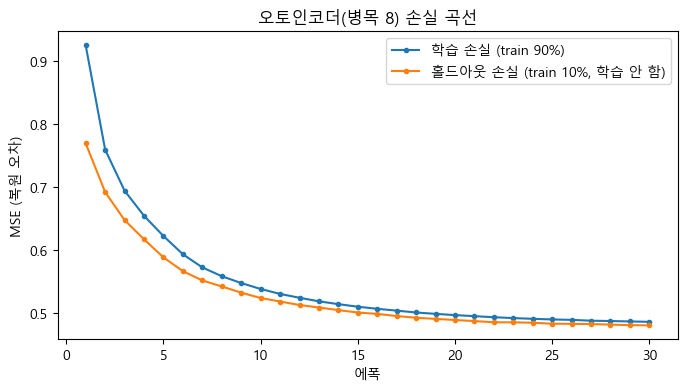

In [11]:
plt.figure(figsize=(8, 4))
epochs = range(1, len(history8['학습 손실']) + 1)
plt.plot(epochs, history8['학습 손실'], marker='o', markersize=3, label='학습 손실 (train 90%)')
plt.plot(epochs, history8['홀드아웃 손실'], marker='o', markersize=3, label='홀드아웃 손실 (train 10%, 학습 안 함)')
plt.xlabel('에폭')
plt.ylabel('MSE (복원 오차)')
plt.title('오토인코더(병목 8) 손실 곡선')
plt.legend()
plt.show()

## 6. 재구성 오차로 채점

거래마다 "31개 피처의 복원 오차 제곱의 평균"을 이상 점수로 씁니다.

contamination threshold를 두 가지 기준으로 정해서 비교합니다.
- **학습에 쓴 train(90%) 점수 기준**: 모델이 이 거래들을 학습했으니 오차가 작게 나올 수 있음 → threshold가 너무 낮아질 위험
- **홀드아웃(10%) 점수 기준**: 학습에 안 쓴 거래라 val·test와 같은 조건

PCA k=28, 거리 단독과 같은 표에서 비교하고, 재구성 오차가 평면 이탈 거리와 얼마나 같이 움직이는지(순위 상관)도 봅니다.

In [12]:
def recon_error(model, X):
    # 거래마다 31개 피처의 (복원값 - 입력)^2 평균
    model.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        return ((model(X_t) - X_t) ** 2).mean(dim=1).numpy()

err_fit, err_hold, err_va = recon_error(ae8, X_fit), recon_error(ae8, X_hold), recon_error(ae8, X_va)

q = 1 - val_contamination
print(f'오차 상위 0.1055% 지점 — 학습용 train: {np.quantile(err_fit, q):.3f} / 홀드아웃: {np.quantile(err_hold, q):.3f}')

rho = round(float(spearmanr(err_va, dist_val).correlation), 3)
ae_rows = [
    evaluate('AE 병목 8 (threshold: 학습용 train)', err_fit, err_va),
    evaluate('AE 병목 8 (threshold: 홀드아웃)', err_hold, err_va),
]
for row in ae_rows:
    row['평면 이탈 거리와 순위 상관'] = rho

pca28 = pca_results[pca_results['모델'] == 'PCA k=28']
comparison = pd.concat([pd.DataFrame(results), pca28, pd.DataFrame(ae_rows)], ignore_index=True)
display(comparison)

오차 상위 0.1055% 지점 — 학습용 train: 11.224 / 홀드아웃: 9.895


,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC,평면 밖 배수,평면 위 배수,평면 이탈 거리와 순위 상관
0,평면 이탈 거리 단독 (기준),0.8332,0.7907,25,0.6773,0.9250,108.7,1.5,NaN
1,PCA k=28,0.8749,0.8447,28,0.7082,0.9659,121.4,4.6,0.147
2,AE 병목 8 (threshold: 학습용 train),0.5785,0.5353,26,0.0615,0.9384,27.9,3.3,0.386
3,AE 병목 8 (threshold: 홀드아웃),0.5785,0.5328,30,0.0615,0.9384,27.9,3.3,0.386


## 7. 병목 크기 실험

PCA에서는 k=28만 유독 강했습니다. 오토인코더도 병목이 너무 좁아서(8) 부진했을 가능성이 있으니, 병목 크기를 4 / 8 / 16 / 24 / 28로 바꿔봅니다.

**주의 1 — 진짜 병목은 가장 좁은 층**: 지금까지 구조는 31 → 16 → 병목 → 16 → 31이라, 병목을 24나 28로 해도 앞의 16짜리 층에서
정보가 막혀 실제 병목은 16이 됩니다. 그래서 이 실험은 모든 크기에서 **은닉층 너비를 32로 통일**합니다 (31 → 32 → 병목 → 32 → 31).

**주의 2 — 고르는 게 아니라 민감도 확인**: val 성능이 가장 좋은 병목을 고르면 threshold 때와 같은 과적합입니다.
이 실험의 목적은 "병목 크기에 따라 결과가 얼마나 흔들리는지" 보는 것입니다.

threshold는 홀드아웃 점수 기준으로 정합니다. 5번 학습해서 3분 정도 걸립니다.

In [13]:
bottleneck_rows = []
histories = {}
for b in [4, 8, 16, 24, 28]:
    model_b, hist_b = train_autoencoder(bottleneck=b, X_fit=X_fit, X_hold=X_hold, hidden=32)
    histories[b] = hist_b
    e_hold, e_va = recon_error(model_b, X_hold), recon_error(model_b, X_va)

    row = evaluate(f'AE 병목 {b} (은닉 32)', e_hold, e_va)
    row['홀드아웃 손실'] = round(hist_b['홀드아웃 손실'][-1], 4)    # 평균 복원 오차 (낮을수록 복원을 잘함)
    row['평면 이탈 거리와 순위 상관'] = round(float(spearmanr(e_va, dist_val).correlation), 3)
    bottleneck_rows.append(row)
    print(f'병목 {b} 완료 (홀드아웃 손실 {row["홀드아웃 손실"]})')

bottleneck_results = pd.DataFrame(bottleneck_rows)
display(pd.concat([pd.DataFrame(results), pca28, bottleneck_results], ignore_index=True))

병목 4 완료 (홀드아웃 손실 0.5157)
병목 8 완료 (홀드아웃 손실 0.3137)
병목 16 완료 (홀드아웃 손실 0.1344)
병목 24 완료 (홀드아웃 손실 0.035)
병목 28 완료 (홀드아웃 손실 0.012)


,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC,평면 밖 배수,평면 위 배수,평면 이탈 거리와 순위 상관,홀드아웃 손실
0,평면 이탈 거리 단독 (기준),0.8332,0.7907,25,0.6773,0.9250,108.7,1.5,NaN,NaN
1,PCA k=28,0.8749,0.8447,28,0.7082,0.9659,121.4,4.6,0.147,NaN
2,AE 병목 4 (은닉 32),0.5936,0.5436,38,0.0718,0.9031,21.9,3.2,0.398,0.5157
3,AE 병목 8 (은닉 32),0.6710,0.6638,37,0.1432,0.9271,33.8,12.6,0.419,0.3137
4,AE 병목 16 (은닉 32),0.6506,0.6489,57,0.1115,0.9533,39.9,11.4,0.386,0.1344
5,AE 병목 24 (은닉 32),0.6423,0.6089,34,0.1201,0.9614,36.3,3.4,0.287,0.0350
6,AE 병목 28 (은닉 32),0.6051,0.5373,23,0.0656,0.9222,36.3,1.9,0.053,0.0120


### 병목 크기별: 사기 탐지 성능 vs 평균 복원 품질

왼쪽: 같은 압축 크기에서 PCA(선형)와 오토인코더(비선형)의 사기 탐지 성능(PR-AUC).
오른쪽: 오토인코더의 평균 복원 오차(홀드아웃 손실). 복원을 잘하는 것과 사기를 잘 찾는 것이 같은 방향인지 봅니다.

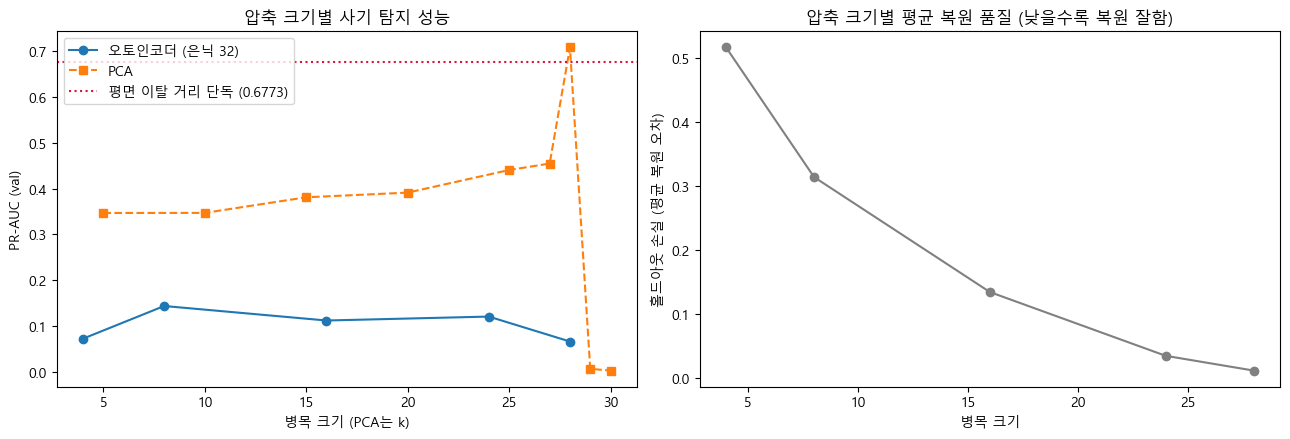

In [14]:
sizes = [4, 8, 16, 24, 28]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(sizes, bottleneck_results['PR-AUC'], marker='o', label='오토인코더 (은닉 32)')
axes[0].plot(ks, pca_results['PR-AUC'], marker='s', linestyle='--', label='PCA')
axes[0].axhline(results[0]['PR-AUC'], color='crimson', linestyle=':', label=f"평면 이탈 거리 단독 ({results[0]['PR-AUC']})")
axes[0].set_xlabel('병목 크기 (PCA는 k)')
axes[0].set_ylabel('PR-AUC (val)')
axes[0].set_title('압축 크기별 사기 탐지 성능')
axes[0].legend()

axes[1].plot(sizes, bottleneck_results['홀드아웃 손실'], marker='o', color='gray')
axes[1].set_xlabel('병목 크기')
axes[1].set_ylabel('홀드아웃 손실 (평균 복원 오차)')
axes[1].set_title('압축 크기별 평균 복원 품질 (낮을수록 복원 잘함)')

plt.tight_layout()
plt.show()

## 8. PCA k=28은 왜 통했나: 뒤쪽 성분 분석

k=28은 25번째가 아니라 **29, 30, 31번째 성분을 버립니다.** 버린 성분에 사기 신호가 있었다는 뜻이니, 뒤쪽 성분들이 각각 무엇인지 봅니다.

**평면 위 거래끼리의 분산 비율**: 평면 위 거래(88%)들만 모아서 그 성분 값이 얼마나 흩어져 있는지를 전체 대비 비율로 봅니다.
0에 가까우면 "평면 위 거래들은 이 방향으로 전부 같은 값" → 그 성분이 곧 **평면 방향**이라는 뜻입니다.
(평면 위/밖 구분은 채점이 아니라 해석용으로만 씁니다. PCA 자체는 정답도 평면 정보도 없이 학습했습니다.)

In [15]:
Z_tr, Z_va = pca_full.transform(X_tr), pca_full.transform(X_va)   # 각 거래의 성분별 점수
on_plane_train = dist_train < 1e-6

rows = []
for j in range(24, 31):   # 25~31번째 성분 (0부터 세므로 24~30)
    top = np.argsort(-np.abs(pca_full.components_[j]))[:4]   # 가중치가 큰 피처 4개
    rows.append({
        '성분': j + 1,
        '분산': round(float(pca_full.explained_variance_[j]), 3),
        '평면 위 거래끼리의 분산 비율': round(float(Z_tr[on_plane_train, j].var() / Z_tr[:, j].var()), 4),
        '주요 가중치': ', '.join(f'{cols_C[i]}({pca_full.components_[j][i]:+.2f})' for i in top),
    })
display(pd.DataFrame(rows))

,성분,분산,평면 위 거래끼리의 분산 비율,주요 가중치
0,25,0.973,0.6953,"V23(+0.61), V21(+0.40), V25(-0.30), V5(+0.23)"
1,26,0.951,0.9360,"V5(+0.38), V27(-0.33), V2(-0.32), V22(+0.29)"
2,27,0.938,0.8443,"V28(+0.48), V27(+0.46), V1(+0.38), V7(+0.24)"
3,28,0.870,0.8154,"V20(+0.54), V28(+0.50), V23(-0.37), V27(-0.27)"
4,29,0.687,0.0125,"V17(+0.46), V14(+0.35), V12(+0.32), V10(+0.32)"
5,30,0.379,0.9404,"hour_sin(+0.53), hour_cos(+0.49), V12(+0.35), ..."
6,31,0.368,0.9799,"log_amount(+0.63), V2(+0.48), V5(+0.29), hour_..."


### 29번째 성분 값의 크기: 정상 vs 사기

위 표에서 평면 방향으로 보이는 29번째 성분에서, 그룹별로 성분 값의 크기(절댓값)를 비교합니다. 값의 범위가 넓어서 로그 눈금으로 그립니다.

정상 (평면 위): 25111건, 평균 0.063, 중앙값 0.048
정상 (평면 밖): 3321건, 평균 0.154, 중앙값 0.109
사기 (평면 밖): 25건, 평균 25.431, 중앙값 24.138
사기 (평면 위): 5건, 평균 0.059, 중앙값 0.035


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

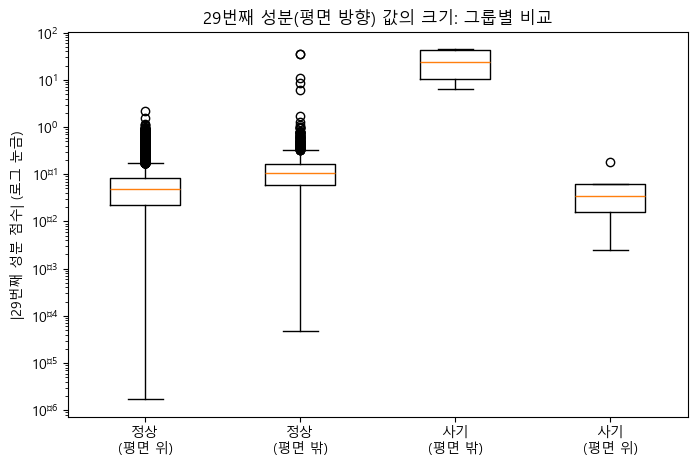

In [16]:
comp29 = np.abs(Z_va[:, 28])   # 29번째 성분 점수의 크기
groups = {
    '정상\n(평면 위)': comp29[(y_true == 0) & on_plane_val],
    '정상\n(평면 밖)': comp29[(y_true == 0) & ~on_plane_val],
    '사기\n(평면 밖)': comp29[(y_true == 1) & ~on_plane_val],
    '사기\n(평면 위)': comp29[(y_true == 1) & on_plane_val],
}
for name, values in groups.items():
    print(f"{name.replace(chr(10), ' ')}: {len(values)}건, 평균 {values.mean():.3f}, 중앙값 {np.median(values):.3f}")

plt.figure(figsize=(8, 5))
plt.boxplot([np.maximum(v, 1e-6) for v in groups.values()], tick_labels=list(groups.keys()))
plt.yscale('log')
plt.ylabel('|29번째 성분 점수| (로그 눈금)')
plt.title('29번째 성분(평면 방향) 값의 크기: 그룹별 비교')
plt.show()

**정리: PCA는 평면을 찾았지만, "우연히 세 번째로 작은 방향"이었다**
- 30, 31번째 성분은 우리가 만든 피처(시간대 sin/cos, log 금액)가 차지 → 평면과 무관
- 29번째 성분이 평면 방향 → k=28은 이걸 버려서 재구성 오차에 사기 신호가 담기고, k=29는 이걸 남겨서 신호가 사라짐
- 그래서 k=28의 성공은 "평면 방향보다 분산이 작은 성분이 몇 개냐"에 달려 있어서 불안정합니다. 피처 구성이 바뀌면(예: 시간대 피처를 빼면)
  맞는 k도 바뀝니다. 앞에서 "PCA는 평면을 못 찾는다"고 한 건 가장 작은 두 성분만 보고 내린 결론이라 틀렸습니다.

## 9. 네 번째 제출 파일: PCA k=28 재구성 오차

val에서 지금까지 가장 좋았던 PCA k=28(contamination macro-F1 0.8447, PR-AUC 0.7082)이 리더보드에서도 통하는지 확인합니다.
k=28은 val을 보고 고른 게 아니라 "누적 설명 분산 95%" 규칙으로 정해진 값입니다. threshold는 지금까지와 같은 contamination 방식입니다.

비교 기준 (현재 최고): 평면 이탈 거리 단독 → Public 0.8294 / Private 0.8306

In [17]:
pca28_model = PCA(n_components=28).fit(X_tr)

def pca28_error(X):
    # 28개 성분으로 압축했다가 복원했을 때의 오차 제곱합
    return ((X - pca28_model.inverse_transform(pca28_model.transform(X))) ** 2).sum(axis=1)

err28_tr, err28_te = pca28_error(X_tr), pca28_error(X_te)
threshold = np.quantile(err28_tr, 1 - val_contamination)   # train 점수 기준 (val 정답은 안 봄)
pred_pca = (err28_te >= threshold).astype(int)

pd.DataFrame({'ID': test_fe['ID'], 'Class': pred_pca}).to_csv('../submissions/submission_phase4_pca_k28.csv', index=False)
print(f'PCA k=28: test 사기 예측 {pred_pca.sum()}건 ({pred_pca.mean() * 100:.3f}%) -> submissions/submission_phase4_pca_k28.csv')

# 현재 최고 제출(평면 이탈 거리 단독)의 test 예측과 얼마나 겹치는지
dist_test = test_fe['off_plane_dist'].values
pred_dist = (dist_test >= np.quantile(dist_train, 1 - val_contamination)).astype(int)
print(f'평면 이탈 거리 단독: test 사기 예측 {pred_dist.sum()}건')
print(f'둘 다 사기로 찍은 거래: {(pred_pca & pred_dist).sum()}건 / PCA만: {(pred_pca & ~pred_dist.astype(bool)).sum()}건 / 거리만: {(pred_dist & ~pred_pca.astype(bool)).sum()}건')

PCA k=28: test 사기 예측 262건 (0.184%) -> submissions/submission_phase4_pca_k28.csv
평면 이탈 거리 단독: test 사기 예측 266건
둘 다 사기로 찍은 거래: 226건 / PCA만: 36건 / 거리만: 40건


## 10. 실험: 구조(압축형 vs 확장형) × 점수(MSE vs 코사인)

Dacon에 공유된 다른 오토인코더 코드는 우리와 두 가지가 다릅니다.
- **구조**: 인코더에서 차원을 **늘렸다가** 디코더에서 줄이는 확장형 (우리는 줄였다가 늘리는 압축형)
- **점수**: 입력과 복원값의 **코사인 유사도** (우리는 MSE)

두 가지를 2 × 2로 조합해서 같은 기준으로 비교합니다.

| | MSE | 코사인 거리 |
|---|---|---|
| 압축형 31 → 32 → 8 → 32 → 31 | 우리 방식 | |
| 확장형 31 → 64 → 128 → 64 → 31 | | 공유된 코드 방식 |

**MSE vs 코사인 거리**
- MSE: 입력과 복원값의 **값 차이**. 크기와 방향이 모두 반영됩니다.
- 코사인 거리 = 1 - 코사인 유사도: 두 벡터가 가리키는 **방향 차이**만 봅니다. 크기는 무시합니다.

**미리 세운 가설 2개**
1. 확장형은 병목이 없어서 "입력을 그대로 베끼기"를 배우기 쉽고, 그러면 사기도 잘 복원해서 성능이 떨어질 것이다.
2. 표준화된 데이터에서 평범한 거래는 원점(0) 근처의 짧은 벡터라, 방향이 조금만 흔들려도 코사인 거리가 커진다.
   그래서 코사인 점수는 **평범한 거래를 이상치로 찍을** 수 있다.
   → 확인 방법: 점수 상위 30건 거래의 "입력 벡터 크기"가 전체보다 작게 나오는지 봅니다.

모델 2개를 학습해서 1~2분 걸립니다. threshold는 홀드아웃 점수 기준입니다.

In [18]:
def recon_scores(model, X):
    # 복원 결과로 두 가지 점수를 계산
    model.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        out = model(X_t)
        mse = ((out - X_t) ** 2).mean(dim=1)                          # 값 차이
        cos = torch.nn.functional.cosine_similarity(out, X_t, dim=1)   # 방향이 같을수록 1
    return mse.numpy(), (1 - cos).numpy()                              # 코사인 거리: 클수록 방향이 다름

variants = {
    '압축형 (31→32→8→32→31)': dict(bottleneck=8, hidden=32),
    '확장형 (31→64→128→64→31)': dict(bottleneck=128, hidden=64),
}

input_norm_va = np.linalg.norm(X_va, axis=1)   # 각 val 거래의 입력 벡터 크기 (원점에서의 거리)
score_rows = []
for name, cfg in variants.items():
    model, hist = train_autoencoder(X_fit=X_fit, X_hold=X_hold, **cfg)
    mse_hold, cos_hold = recon_scores(model, X_hold)
    mse_va, cos_va = recon_scores(model, X_va)

    for score_name, s_hold, s_va in [('MSE', mse_hold, mse_va), ('코사인 거리', cos_hold, cos_va)]:
        row = evaluate(f'{name} + {score_name}', s_hold, s_va)
        row['홀드아웃 손실(MSE)'] = round(hist['홀드아웃 손실'][-1], 4)
        top30 = np.argsort(-s_va)[:30]   # 점수 상위 30건
        row['상위30 입력크기 중앙값'] = round(float(np.median(input_norm_va[top30])), 2)
        score_rows.append(row)
    print(name, '완료')

print('참고: val 전체 입력크기 중앙값', round(float(np.median(input_norm_va)), 2),
      '/ val 사기 입력크기 중앙값', round(float(np.median(input_norm_va[y_true == 1])), 2))
display(pd.concat([pd.DataFrame(results), pca28, pd.DataFrame(score_rows)], ignore_index=True))

압축형 (31→32→8→32→31) 완료
확장형 (31→64→128→64→31) 완료
참고: val 전체 입력크기 중앙값 4.49 / val 사기 입력크기 중앙값 18.45


,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC,평면 밖 배수,평면 위 배수,평면 이탈 거리와 순위 상관,홀드아웃 손실(MSE),상위30 입력크기 중앙값
0,평면 이탈 거리 단독 (기준),0.8332,0.7907,25,0.6773,0.9250,108.7,1.5,NaN,NaN,NaN
1,PCA k=28,0.8749,0.8447,28,0.7082,0.9659,121.4,4.6,0.147,NaN,NaN
2,압축형 (31→32→8→32→31) + MSE,0.6710,0.6638,37,0.1432,0.9271,33.8,12.6,NaN,0.3137,40.43
3,압축형 (31→32→8→32→31) + 코사인 거리,0.5200,0.5156,32,0.0024,0.1833,0.6,84.8,NaN,0.3137,6.13
4,확장형 (31→64→128→64→31) + MSE,0.6294,0.6076,44,0.1081,0.9289,32.0,20.5,NaN,0.0003,33.30
5,확장형 (31→64→128→64→31) + 코사인 거리,0.5056,0.4995,22,0.0036,0.7339,3.8,4.6,NaN,0.0003,6.45


## 11. 교훈 적용: 우리 구조에서도 L1 손실이 핵심일까?

04b 노트북의 절제 실험에서, 공유 코드가 잘 되는 핵심 요소는 **학습 손실 L1**이었습니다 (MSE로 바꾸면 평면 밖 사기 적중 24건 → 1건).
그런데 Phase 4의 우리 오토인코더들은 전부 **MSE 손실**로 학습했습니다. 그래서 앞에서 내린 결론들
("오토인코더는 평면을 못 찾는다", "코사인 점수는 쓸모없다")은 "MSE 손실이라면"이라는 조건이 붙어야 했습니다.

여기서는 우리 파이프라인(세트 C 표준화 입력, 30 에폭, 학습률 0.001, 배치 512, 홀드아웃 threshold)은 그대로 두고
**구조 × 학습 손실**을 2 × 2로 비교합니다. 손실만 L1으로 바꿨을 때 우리 구조에서도 살아나는지가 핵심입니다.

| | MSE 학습 | L1 학습 |
|---|---|---|
| 압축형 31 → 32 → 8 → 32 → 31 | 섹션 10과 같은 설정 | |
| 확장형 31 → 64 → 128 → 64 → 31 | 섹션 10과 같은 설정 | |

- **L1 손실**: 오차의 절댓값 평균. 오차가 10배면 벌점도 10배
- **MSE 손실**: 오차 제곱의 평균. 오차가 10배면 벌점은 100배 → 극단적인 거래(사기 포함)까지 복원하려고 애씀

4번 학습해서 3분 정도 걸립니다.

In [ ]:
loss_rows = []
for loss_name in ['MSE', 'L1']:
    for struct_name, cfg in variants.items():   # 섹션 10의 압축형·확장형 설정 재사용
        model, hist = train_autoencoder(X_fit=X_fit, X_hold=X_hold, loss=loss_name, **cfg)
        mse_hold, cos_hold = recon_scores(model, X_hold)
        mse_va, cos_va = recon_scores(model, X_va)
        for score_name, s_hold, s_va in [('MSE', mse_hold, mse_va), ('코사인 거리', cos_hold, cos_va)]:
            row = evaluate(f'{struct_name} / {loss_name} 학습 / {score_name} 점수', s_hold, s_va)
            pred = s_va >= np.quantile(s_hold, 1 - val_contamination)   # contamination threshold로 찍은 거래
            row['맞힌 평면 밖 사기(/25)'] = int((pred & (y_true == 1) & ~on_plane_val).sum())
            loss_rows.append(row)
        print(f'{struct_name} / {loss_name} 학습 완료')

loss_results = pd.DataFrame(loss_rows)
display(loss_results[['모델', 'contamination macro-F1', 'contamination 예측 건수', '맞힌 평면 밖 사기(/25)', 'PR-AUC', '평면 위 배수']])